In [ ]:
#%pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 8.8 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 9.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 7.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [geopandas]
Note: you may need to restart the kernel to use updated packages.


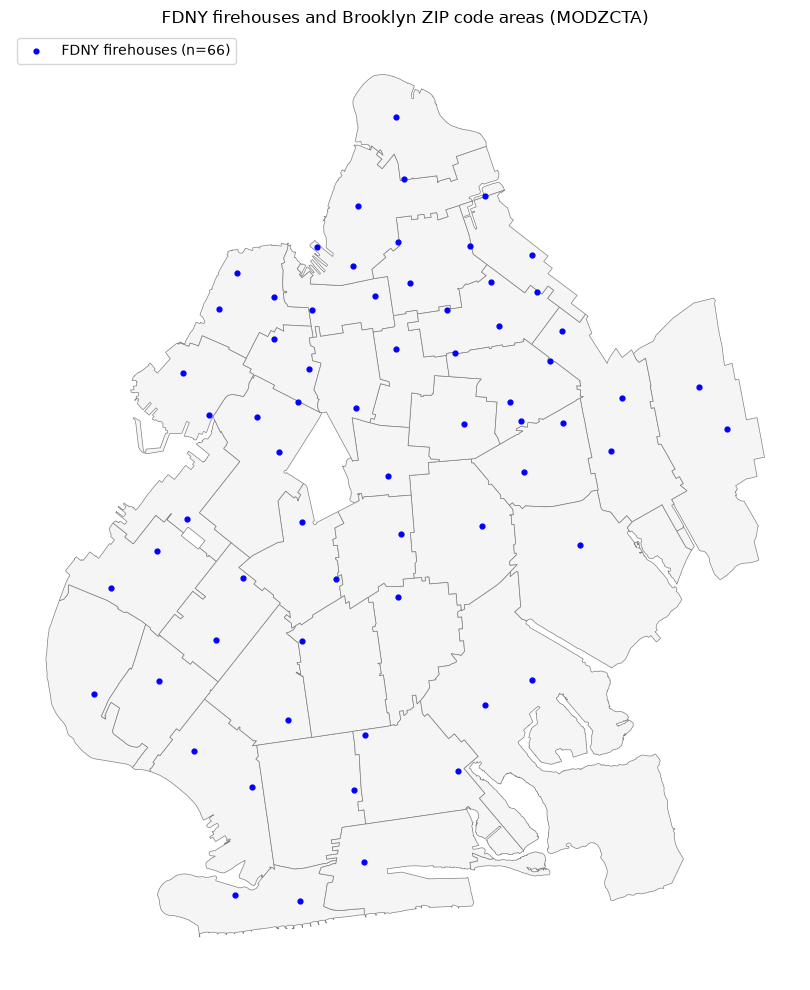

In [4]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# ZIP code area boundaries (MODZCTA). GeoJSON is in longitude/latitude (EPSG:4326).
zips = gpd.read_file("data/modzcta.geojson")

# Firehouse locations: turn the Latitude/Longitude columns into point geometries.
firehouses = pd.read_csv("data/FDNY_Firehouse_Listing_20261115.csv")
firehouses = gpd.GeoDataFrame(
    firehouses,
    geometry=gpd.points_from_xy(firehouses["Longitude"], firehouses["Latitude"]),
    crs="EPSG:4326",
)

# Keep Brooklyn only. The firehouse CSV has a Borough column; the GeoJSON doesn't,
# so polygons are filtered by Brooklyn's ZIP prefix (all Brooklyn ZIPs are 112xx).
firehouses = firehouses[firehouses["Borough"] == "Brooklyn"]
zips = zips[zips["modzcta"].astype(str).str.startswith("112")]

fig, ax = plt.subplots(figsize=(10, 10))

# Polygons first, then the dots on top.
zips.plot(ax=ax, facecolor="whitesmoke", edgecolor="gray", linewidth=0.5)
firehouses.plot(
    ax=ax,
    color="blue",
    markersize=12,
    label=f"FDNY firehouses (n={len(firehouses)})",
)

ax.set_title("FDNY firehouses and Brooklyn ZIP code areas (MODZCTA)")
ax.legend(loc="upper left")
ax.set_axis_off()

plt.tight_layout()
plt.savefig("firehouses_map_brooklyn.png", dpi=200, bbox_inches="tight")
plt.show()